# 07 - Explainability: SHAP, permutation importance and LIME

Three complementary views of how the models use their inputs, computed on held-out test
loans by `scripts/generate_reports.py` (tables under `reports/metrics/<feature_set>/`):

* **SHAP** - exact additive attributions in log-odds (TreeSHAP for LightGBM, linear SHAP for
  logistic regression, the latter from stored training means - no training rows needed).
* **Permutation feature importance (PFI)** - loss in test ROC-AUC / log loss / Brier when an
  input, or a *group* of related inputs, is shuffled.
* **LIME** - local weighted linear surrogates around individual applicants, with fidelity
  (R2) and stability checks.

None of these measure causal effects; correlated inputs can share or swap attributions.

> Notebooks display **aggregates only** (no individual loan records) and reuse functions from `src/creditiq/`. Educational project - not for real lending decisions.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from creditiq.config import load_config, setup_logging
from creditiq.cli import processed_path, clean_all_path
from creditiq.reporting import figures as figs

setup_logging("WARNING")
cfg = load_config()
figs.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TARGET = cfg["target"]["name"]

In [2]:
import shap
from creditiq.reporting.results import load_results
from creditiq.data.split import split_frames
from creditiq.models.predict import load_model
from creditiq.explainability.shap_analysis import compute_shap, explain_instance
from creditiq.explainability.lime_tabular import explain_lime, lime_stability
from creditiq.models.artifacts import example_application
res = load_results(cfg.path("models_dir"), cfg.path("metrics_dir"), "applicant")
loans = pd.read_parquet(processed_path(cfg))
test = split_frames(loans)["test"]

## SHAP: global importance and direction (both models)

**lightgbm**

,feature,mean_abs_shap,mean_shap,value_shap_spearman
0,term_months,0.301588,0.028885,0.761153
1,revol_util,0.200248,-0.044234,0.987034
2,log_annual_inc,0.167544,0.005186,-0.970121
3,inq_last_6mths,0.151507,-0.024495,0.889028
4,loan_to_income,0.144429,-0.008534,0.968969
5,home_ownership,0.101400,-0.000791,0.903531
6,dti,0.088868,0.017976,0.959471
7,purpose,0.078552,0.000918,0.797888
8,open_to_total_acc,0.073966,0.003843,0.967092
9,open_acc,0.064246,0.008631,0.964385


**logistic_regression**

,feature,mean_abs_shap,mean_shap,value_shap_spearman
0,term_months,0.296252,0.020758,1.0
1,revol_util,0.219375,-0.043861,1.0
2,log_annual_inc,0.159594,0.006095,-1.0
3,inq_last_6mths,0.145252,-0.023172,1.0
4,log_revol_bal,0.136948,0.015170,-1.0
5,purpose_credit_card,0.112364,0.001251,-1.0
6,loan_to_income,0.101363,0.001880,1.0
7,open_acc,0.094274,0.016071,1.0
8,dti,0.075175,0.015618,1.0
9,loan_amnt,0.074847,0.000073,1.0


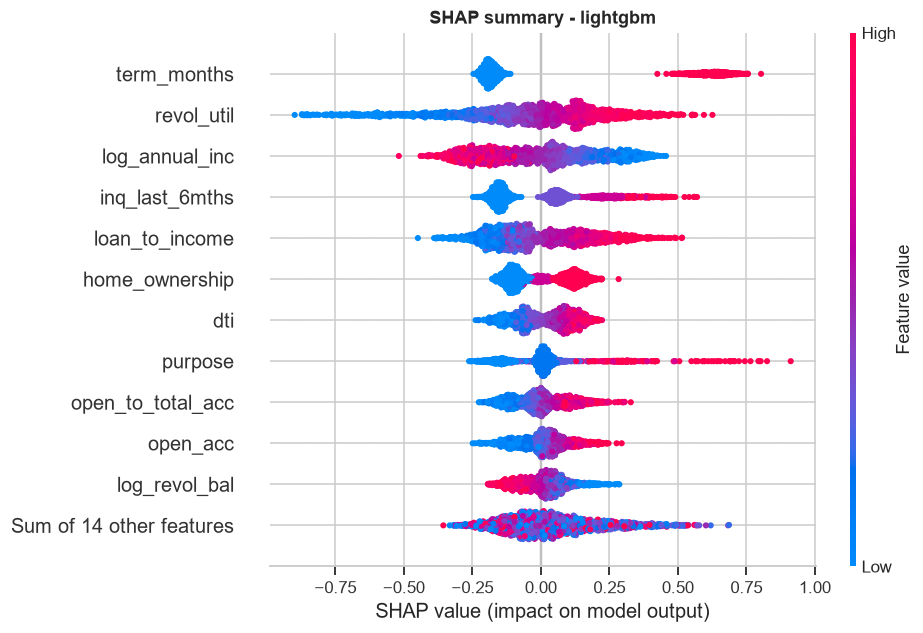

In [3]:
for m in ("lightgbm", "logistic_regression"):
    display(Markdown(f"**{m}**"))
    display(res[f"shap_signed_{m}"].head(10))
sample = test.sample(cfg["evaluation"]["shap_sample_size"], random_state=cfg.seed)
bundle = load_model(cfg.path("models_dir"), "applicant")
shap.plots.beeswarm(compute_shap(bundle, sample).to_explanation(), max_display=12, show=False)
plt.title(f"SHAP summary - {bundle.name}"); plt.show()

## SHAP dependence (binned; line = mean SHAP, band = 10-90%)

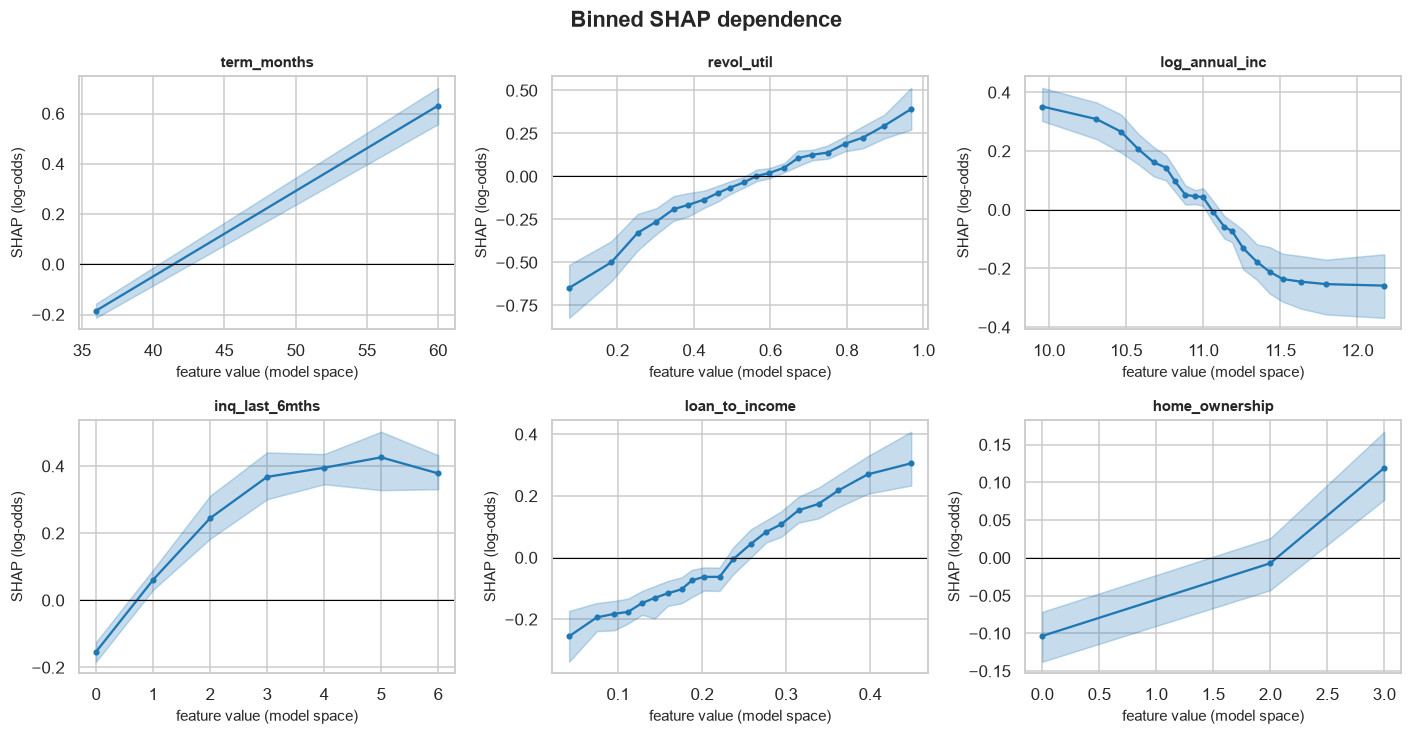

In [4]:
dep = res[f"shap_dependence_{bundle.name}"]
figs.plot_dependence(dep, res[f"shap_signed_{bundle.name}"]["feature"].tolist(), "Binned SHAP dependence"); plt.show()

## Permutation importance: single inputs vs groups of related inputs

**lightgbm** - single inputs

,feature,roc_auc_drop_mean,roc_auc_drop_std,log_loss_drop_mean,brier_drop_mean
0,term,0.073083,0.003560,0.028644,0.009172
1,annual_inc,0.034276,0.003844,0.013634,0.003949
2,loan_amnt,0.029134,0.004094,0.012673,0.004439
3,revol_util,0.026491,0.001998,0.011477,0.003521
4,open_acc,0.016911,0.001533,0.007127,0.002154
5,inq_last_6mths,0.016661,0.002698,0.006424,0.001977
6,revol_bal,0.014793,0.001584,0.006037,0.001718
7,purpose,0.010083,0.001795,0.004019,0.001241
8,home_ownership,0.008952,0.001679,0.003826,0.001223
9,dti,0.004378,0.001353,0.001819,0.000446


**logistic_regression** - single inputs

,feature,roc_auc_drop_mean,roc_auc_drop_std,log_loss_drop_mean,brier_drop_mean
0,term,0.073361,0.003270,0.030070,0.010300
1,annual_inc,0.034185,0.005272,0.013690,0.003970
2,revol_util,0.028749,0.001086,0.012540,0.003985
3,loan_amnt,0.025249,0.003182,0.010684,0.003703
4,open_acc,0.021283,0.001581,0.009405,0.003056
5,inq_last_6mths,0.017438,0.003350,0.006282,0.001955
6,purpose,0.009978,0.000951,0.004052,0.001336
7,revol_bal,0.009356,0.001061,0.003427,0.000900
8,home_ownership,0.008868,0.001905,0.003717,0.001211
9,dti,0.003798,0.001284,0.001758,0.000509


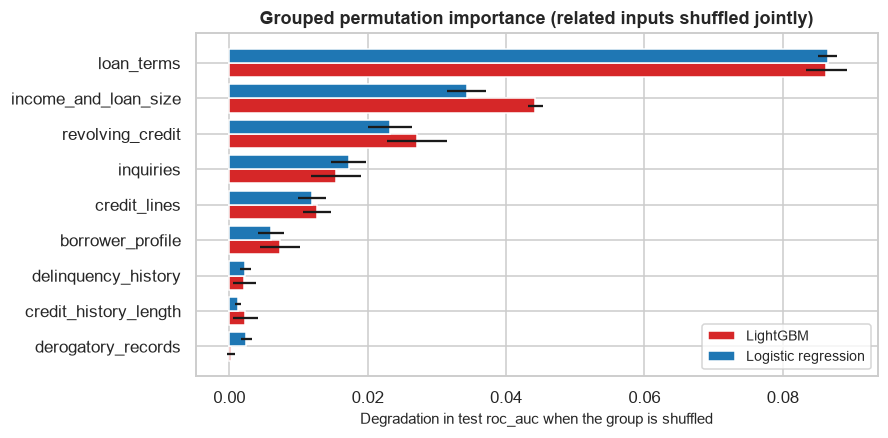

In [5]:
for m in ("lightgbm", "logistic_regression"):
    display(Markdown(f"**{m}** - single inputs"))
    display(res[f"pfi_single_{m}"][["feature", "roc_auc_drop_mean", "roc_auc_drop_std", "log_loss_drop_mean", "brier_drop_mean"]].head(10))
figs.plot_grouped_pfi({m: res[f"pfi_grouped_{m}"] for m in ("lightgbm", "logistic_regression")}); plt.show()

## LIME: global view and one illustrative applicant

lightgbm mean local R2 = 0.446


,feature,mean_abs_lime_weight,mean_local_r2
0,term,0.129508,0.445874
1,annual_inc,0.053198,0.445874
2,revol_util,0.043199,0.445874
3,inq_last_6mths,0.041629,0.445874
4,open_acc,0.034261,0.445874
5,loan_amnt,0.031144,0.445874
6,home_ownership,0.030223,0.445874
7,revol_bal,0.025286,0.445874


logistic_regression mean local R2 = 0.457


,feature,mean_abs_lime_weight,mean_local_r2
0,term,0.140807,0.457393
1,annual_inc,0.056408,0.457393
2,revol_util,0.044458,0.457393
3,inq_last_6mths,0.040241,0.457393
4,open_acc,0.037580,0.457393
5,pub_rec,0.035812,0.457393
6,home_ownership,0.032984,0.457393
7,loan_amnt,0.032798,0.457393


model 0.103 | surrogate 0.109 | R2 0.30


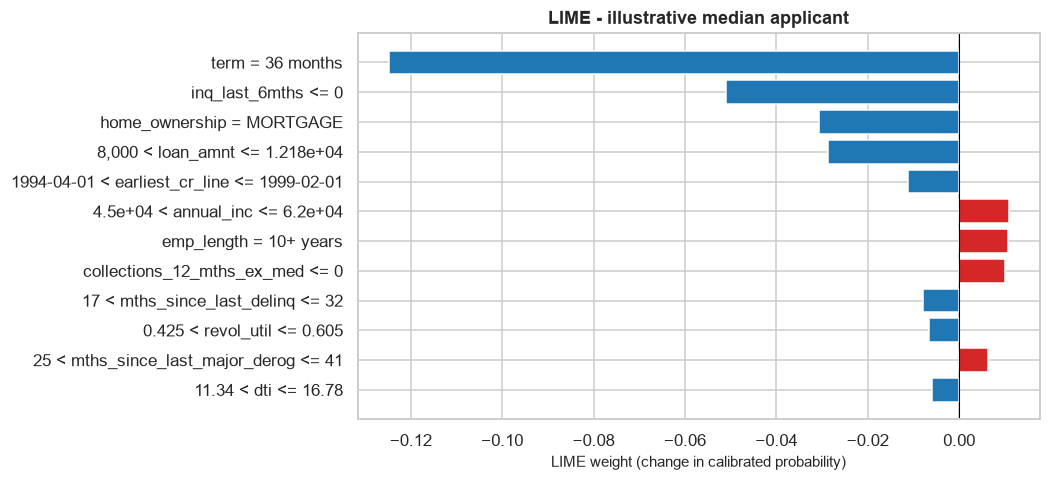

,feature,condition,mean_weight,std_weight,sign_agreement
0,term,term = 36 months,-0.125640,0.004942,1.0
1,inq_last_6mths,inq_last_6mths <= 0,-0.052367,0.002522,1.0
2,home_ownership,home_ownership = MORTGAGE,-0.031743,0.005766,1.0
3,loan_amnt,"8,000 < loan_amnt <= 1.218e+04",-0.026383,0.004614,1.0
4,mths_since_last_record,69 < mths_since_last_record <= 95,0.018300,0.015715,0.8
5,annual_inc,4.5e+04 < annual_inc <= 6.2e+04,0.014775,0.003693,1.0
6,revol_util,0.425 < revol_util <= 0.605,-0.011598,0.004384,1.0
7,pub_rec,pub_rec <= 0,-0.008296,0.008139,1.0


In [6]:
for m in ("lightgbm", "logistic_regression"):
    g = res[f"lime_global_{m}"]
    print(m, "mean local R2 =", round(float(g["mean_local_r2"].iloc[0]), 3))
    display(g.head(8))
app = example_application(bundle.input_schema)   # NOT a real loan
lime = explain_lime(bundle, app, n_samples=cfg["explainability"]["lime_samples"], seed=cfg.seed)
print(f"model {lime.model_prediction:.3f} | surrogate {lime.surrogate_prediction:.3f} | R2 {lime.r2:.2f}")
figs.plot_lime(lime.explanation, "LIME - illustrative median applicant"); plt.show()
display(lime_stability(bundle, app, seeds=tuple(cfg["explainability"]["lime_stability_seeds"]), n_samples=1500).head(8))

## Do SHAP, PFI and LIME agree?

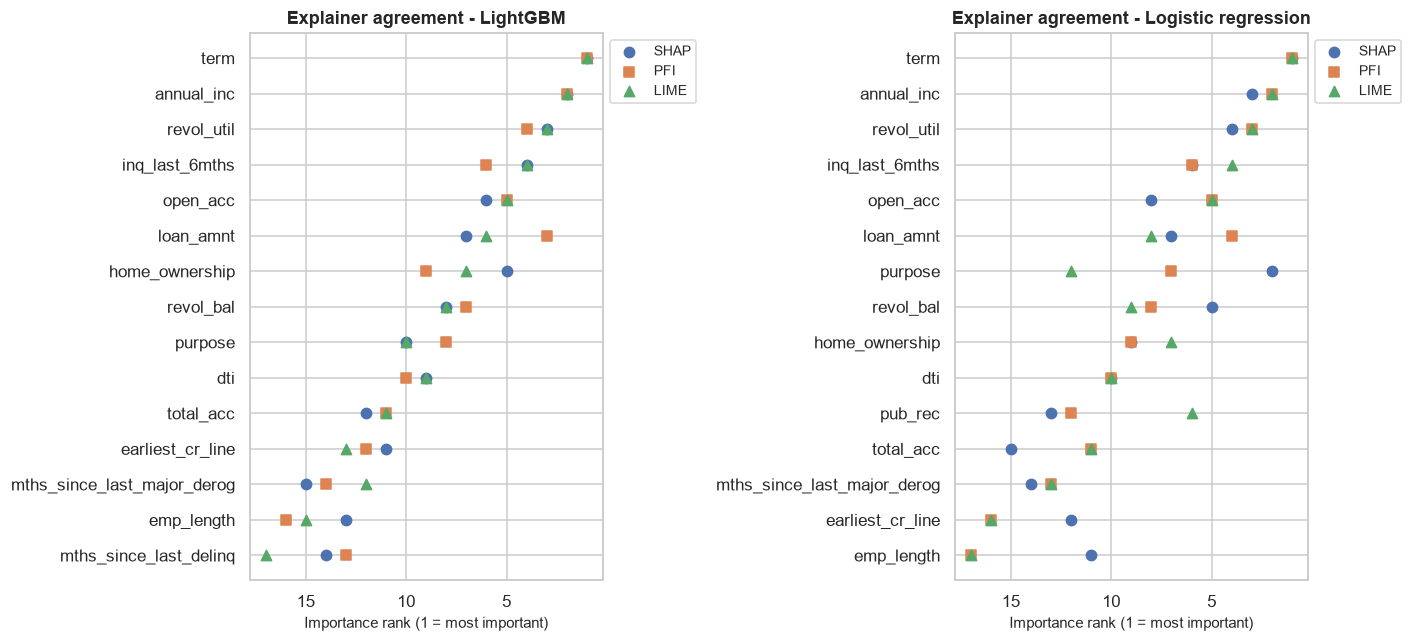

lightgbm


,rank_shap,rank_pfi,rank_lime
rank_shap,1.00,0.95,0.96
rank_pfi,0.95,1.00,0.95
rank_lime,0.96,0.95,1.00


logistic_regression


,rank_shap,rank_pfi,rank_lime
rank_shap,1.00,0.88,0.75
rank_pfi,0.88,1.00,0.90
rank_lime,0.75,0.90,1.00


In [7]:
agr = res["explainer_agreement"]
figs.plot_agreement(agr); plt.show()
for m in dict.fromkeys(agr["model"]):
    g = agr[agr["model"] == m]
    print(m); display(g[["rank_shap", "rank_pfi", "rank_lime"]].corr(method="spearman").round(2))

## Local SHAP for the same illustrative applicant

,feature,model_input_value,shap_log_odds,direction
0,term_months,36.000000,-0.220627,lowers risk
1,inq_last_6mths,0.000000,-0.152057,lowers risk
2,home_ownership,0.000000,-0.095746,lowers risk
3,loan_to_income,0.196371,-0.066526,lowers risk
4,mths_since_last_major_derog,41.000000,0.061952,raises risk
5,mths_since_last_record,95.000000,0.055064,raises risk
6,loan_amnt,12175.000000,-0.035497,lowers risk
7,log_annual_inc,11.034906,0.035066,raises risk
8,revol_bal_to_income,0.200581,-0.032821,lowers risk
9,revol_util,0.605000,0.029321,raises risk


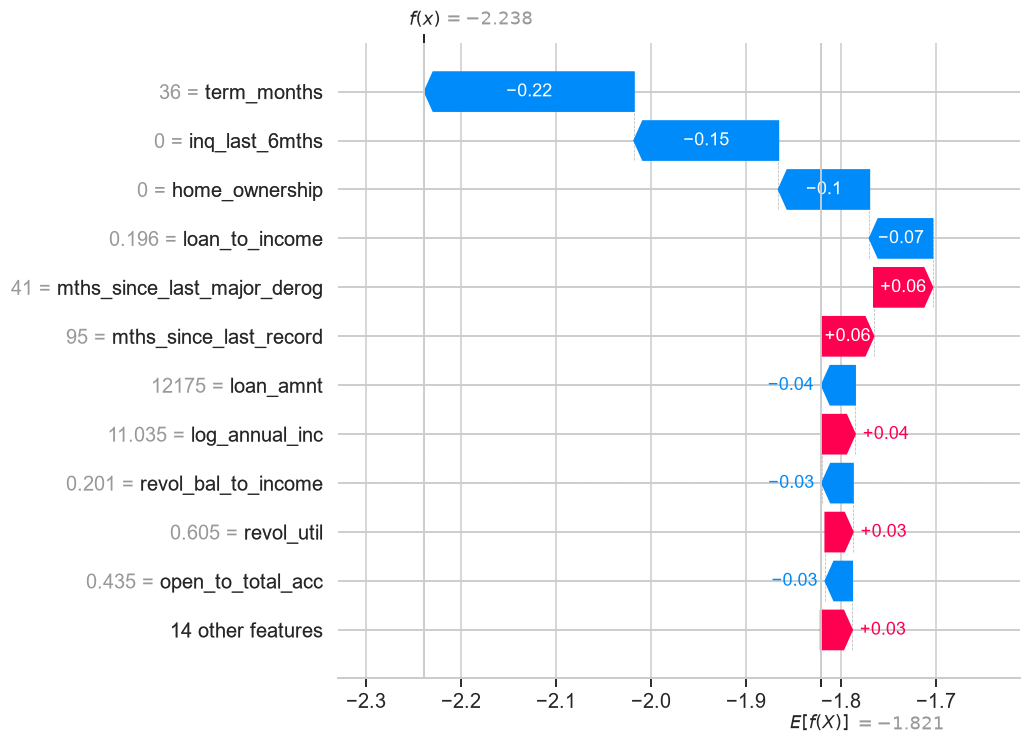

In [8]:
local = compute_shap(bundle, app)
display(explain_instance(local, 0, top_k=10))
shap.plots.waterfall(local.to_explanation()[0], max_display=12, show=False); plt.show()